# Breast Cancer Wisconsin (Diagnostic): EDA, Visualization and Deep Learning

Case study notebook. Pipeline: load → EDA → preprocessing → 12 visualizations → PyTorch MLP (+ grid search) → evaluation visuals → feature importance.

Run all cells top to bottom (about 1–2 minutes on CPU). Figures are also saved to `../figures/`.

In [1]:
%matplotlib inline

```
Exploratory Data Analysis, Visualization and Deep Learning on the
Breast Cancer Wisconsin (Diagnostic) Dataset
=============================================================================
Pipeline (matches the assignment's Project Flow):
    1. Data loading
    2. EDA  (structure, missing values, duplicates, outliers, distributions)
    3. Preprocessing (outlier capping, encoding, scaling, train/val/test split)
    4. Data visualization (univariate, bivariate, multivariate, distributions)
    5. Deep learning model (PyTorch MLP) + basic hyper-parameter tuning
    6. Feature analysis / feature importance
    7. Model evaluation visualization (loss, accuracy, confusion matrix, ROC...)

Run:  python src/analysis.py
Outputs: figures/*.png, results/*.json|csv
```

In [2]:
import json
import os
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

## 0. Configuration

In [3]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = os.path.abspath("..")          # notebook lives in notebooks/
DATA_PATH = os.path.join(ROOT, "data", "breast_cancer_wisconsin.csv")
FIG_DIR = os.path.join(ROOT, "figures")
RES_DIR = os.path.join(ROOT, "results")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

# consistent, colour-blind-friendly palette: Benign = blue, Malignant = orange
PALETTE = {"Benign": "#2a6fb0", "Malignant": "#e0782b"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160,
                     "axes.titleweight": "bold"})
results = {}                                # everything we report goes here


def save(fig, name):
    """Save a figure into figures/ and close it."""
    path = os.path.join(FIG_DIR, name)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("saved", name)

## 1. Data loading

In [4]:
df = pd.read_csv(DATA_PATH)
feature_cols = [c for c in df.columns if c != "diagnosis"]
print("Shape:", df.shape)

results["shape"] = list(df.shape)
results["n_features"] = len(feature_cols)
results["class_counts"] = df["diagnosis"].value_counts().to_dict()

Shape: (569, 31)


## 2. EDA

In [5]:
missing_total = int(df.isna().sum().sum())
duplicates = int(df.duplicated().sum())
results["missing_values"] = missing_total
results["duplicate_rows"] = duplicates
print(f"Missing values: {missing_total} | Duplicate rows: {duplicates}")

desc = df[feature_cols].describe().T
desc["skew"] = df[feature_cols].skew()
desc["kurtosis"] = df[feature_cols].kurt()
desc.round(4).to_csv(os.path.join(RES_DIR, "descriptive_statistics.csv"))

# Outlier detection with the 1.5*IQR rule
outlier_counts = {}
for c in feature_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_counts[c] = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
outliers = pd.Series(outlier_counts).sort_values(ascending=False)
outliers.to_csv(os.path.join(RES_DIR, "outlier_counts_iqr.csv"), header=["n_outliers"])
results["outliers_total_flags"] = int(outliers.sum())
results["outliers_top5"] = outliers.head(5).to_dict()
rows_with_outlier = 0
mask_any = pd.Series(False, index=df.index)
for c in feature_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    mask_any |= (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)
results["rows_with_any_outlier"] = int(mask_any.sum())

# Skewness summary
results["n_skewed_gt1"] = int((desc["skew"].abs() > 1).sum())

# Statistical tests: benign vs malignant for every feature
ben = df[df.diagnosis == "Benign"]
mal = df[df.diagnosis == "Malignant"]
tests = []
for c in feature_cols:
    t, p_t = stats.ttest_ind(mal[c], ben[c], equal_var=False)
    u, p_u = stats.mannwhitneyu(mal[c], ben[c])
    pooled = np.sqrt((mal[c].var() + ben[c].var()) / 2)
    d = (mal[c].mean() - ben[c].mean()) / pooled           # Cohen's d
    tests.append({"feature": c, "mean_malignant": mal[c].mean(),
                  "mean_benign": ben[c].mean(), "cohens_d": d,
                  "t_pvalue": p_t, "mannwhitney_pvalue": p_u})
tests = pd.DataFrame(tests).sort_values("cohens_d", key=np.abs, ascending=False)
tests.to_csv(os.path.join(RES_DIR, "group_tests.csv"), index=False)
results["top_effect_sizes"] = tests.head(5)[["feature", "cohens_d"]].round(2).to_dict("records")
results["n_significant_features_p<0.05"] = int((tests.mannwhitney_pvalue < 0.05).sum())

# Normality tests (continuous distributions)
norm_rows = []
for c in ["mean radius", "mean texture", "mean area", "mean smoothness", "mean concavity"]:
    for cls, g in df.groupby("diagnosis"):
        w, p = stats.shapiro(g[c])
        norm_rows.append({"feature": c, "class": cls, "shapiro_W": w, "p_value": p,
                          "skew": stats.skew(g[c])})
pd.DataFrame(norm_rows).round(4).to_csv(os.path.join(RES_DIR, "normality_tests.csv"), index=False)

# Correlation analysis
corr = df[feature_cols].corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
results["n_pairs_corr_gt_0.9"] = int((pairs.abs() > 0.9).sum())
results["top_corr_pairs"] = [(a, b, round(v, 3)) for (a, b), v in pairs.head(5).items()]

Missing values: 0 | Duplicate rows: 0


## 3. Preprocessing

In [6]:
# (a) Encode target: Malignant = 1 (positive class), Benign = 0
y = (df["diagnosis"] == "Malignant").astype(int).values
X = df[feature_cols].copy()

# (b) Stratified split 70 / 15 / 15  (train / validation / test)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85,
                                                  stratify=y_tmp, random_state=SEED)
results["split_sizes"] = {"train": len(X_train), "val": len(X_val), "test": len(X_test)}

# (c) Outlier handling: winsorize at the 1st/99th percentile.
#     Bounds are learned on TRAIN only (prevents data leakage).
lo, hi = X_train.quantile(0.01), X_train.quantile(0.99)
clip = lambda d: d.clip(lower=lo, upper=hi, axis=1)
X_train_c, X_val_c, X_test_c = clip(X_train), clip(X_val), clip(X_test)

# (d) Standardize (z-score) using TRAIN statistics only
scaler = StandardScaler().fit(X_train_c)
Xtr = scaler.transform(X_train_c)
Xva = scaler.transform(X_val_c)
Xte = scaler.transform(X_test_c)
print("Split:", Xtr.shape, Xva.shape, Xte.shape)

Split: (397, 30) (86, 30) (86, 30)


## 4. Data visualization

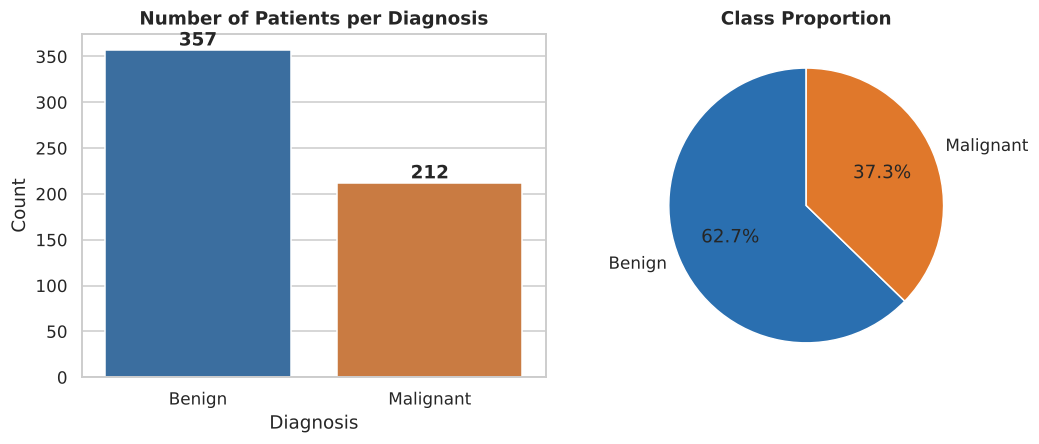

saved 01_class_distribution.png


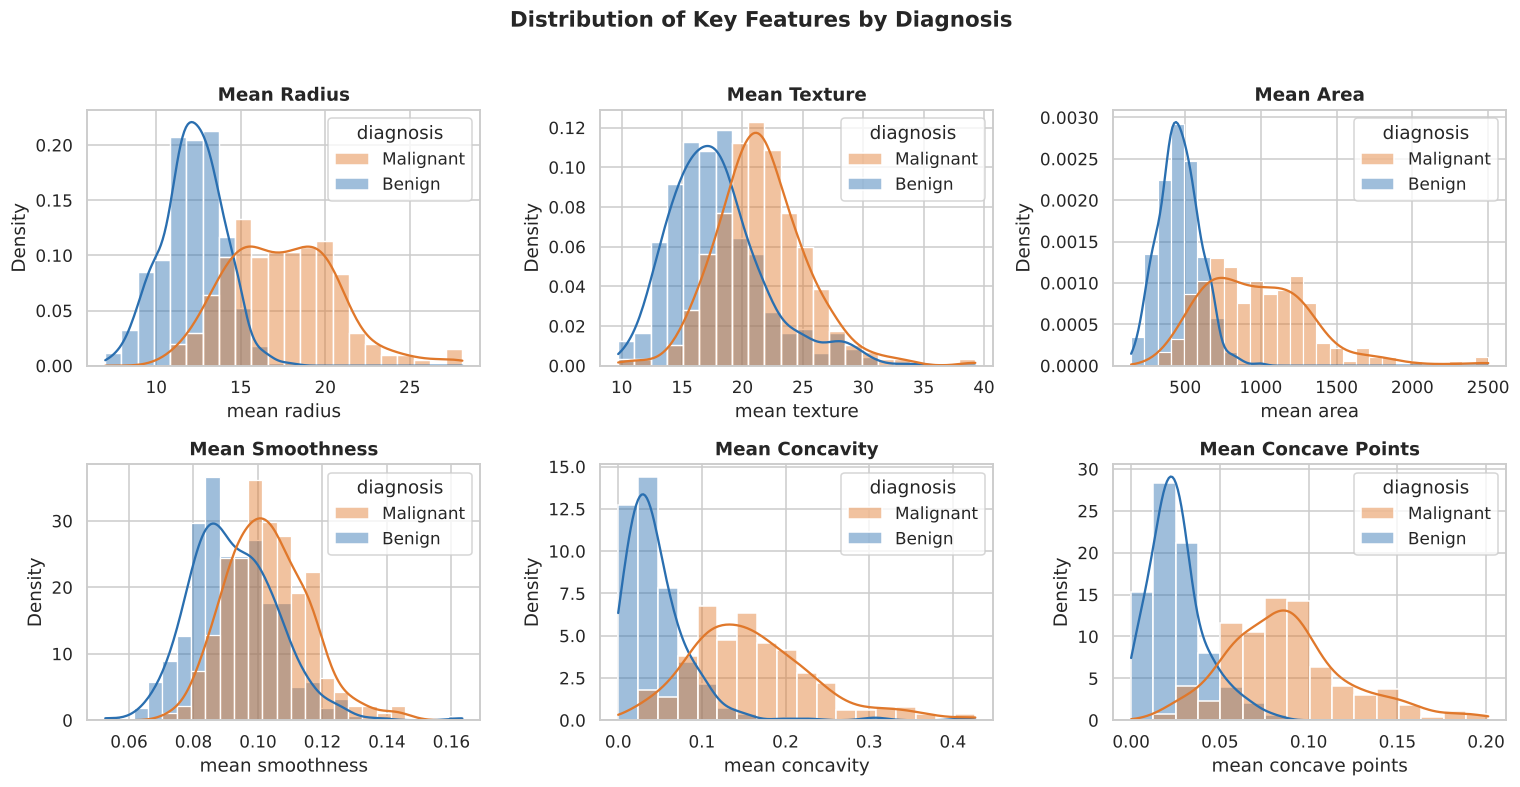

saved 02_histograms_kde.png


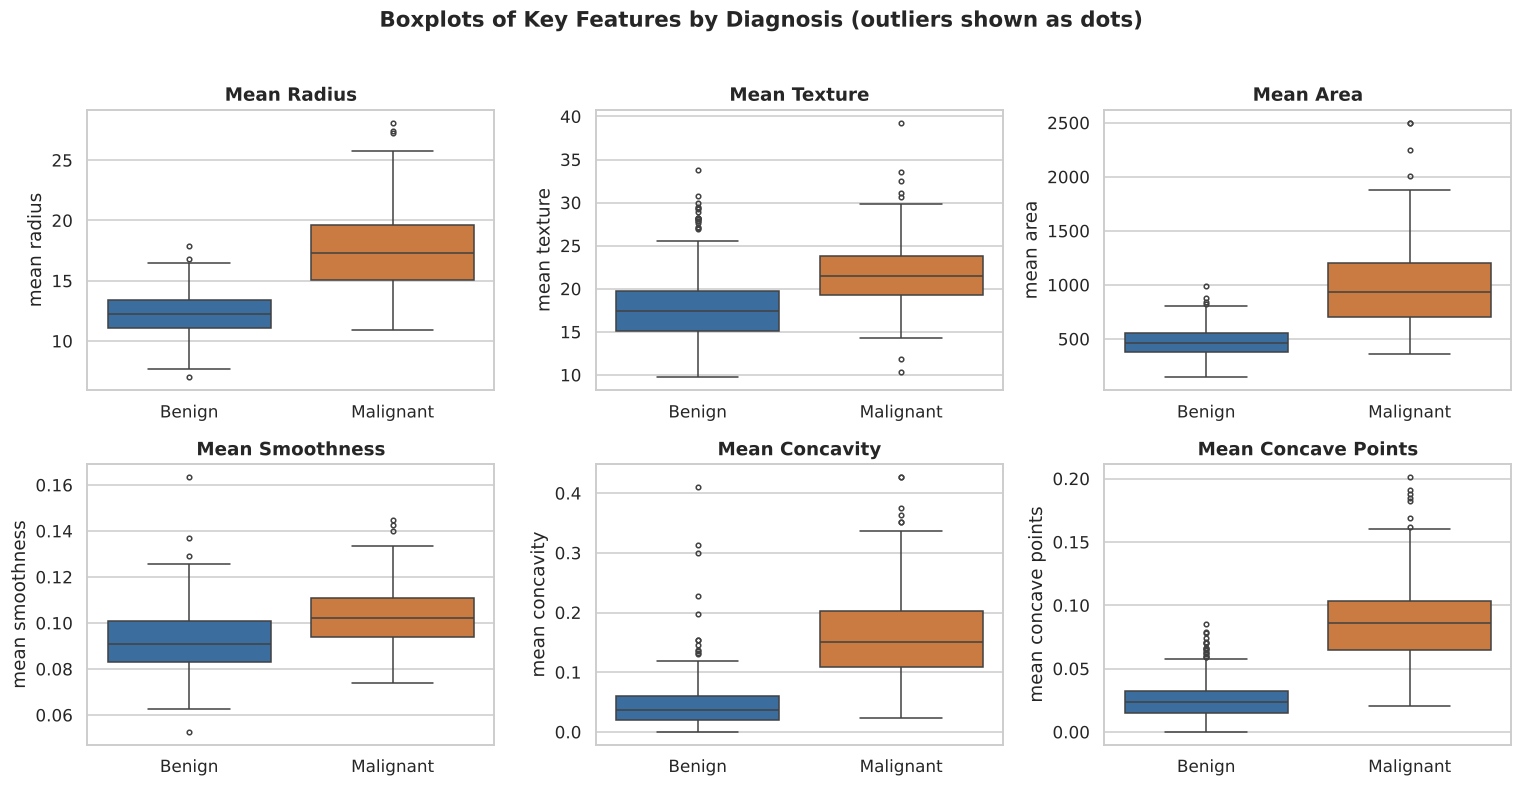

saved 03_boxplots.png


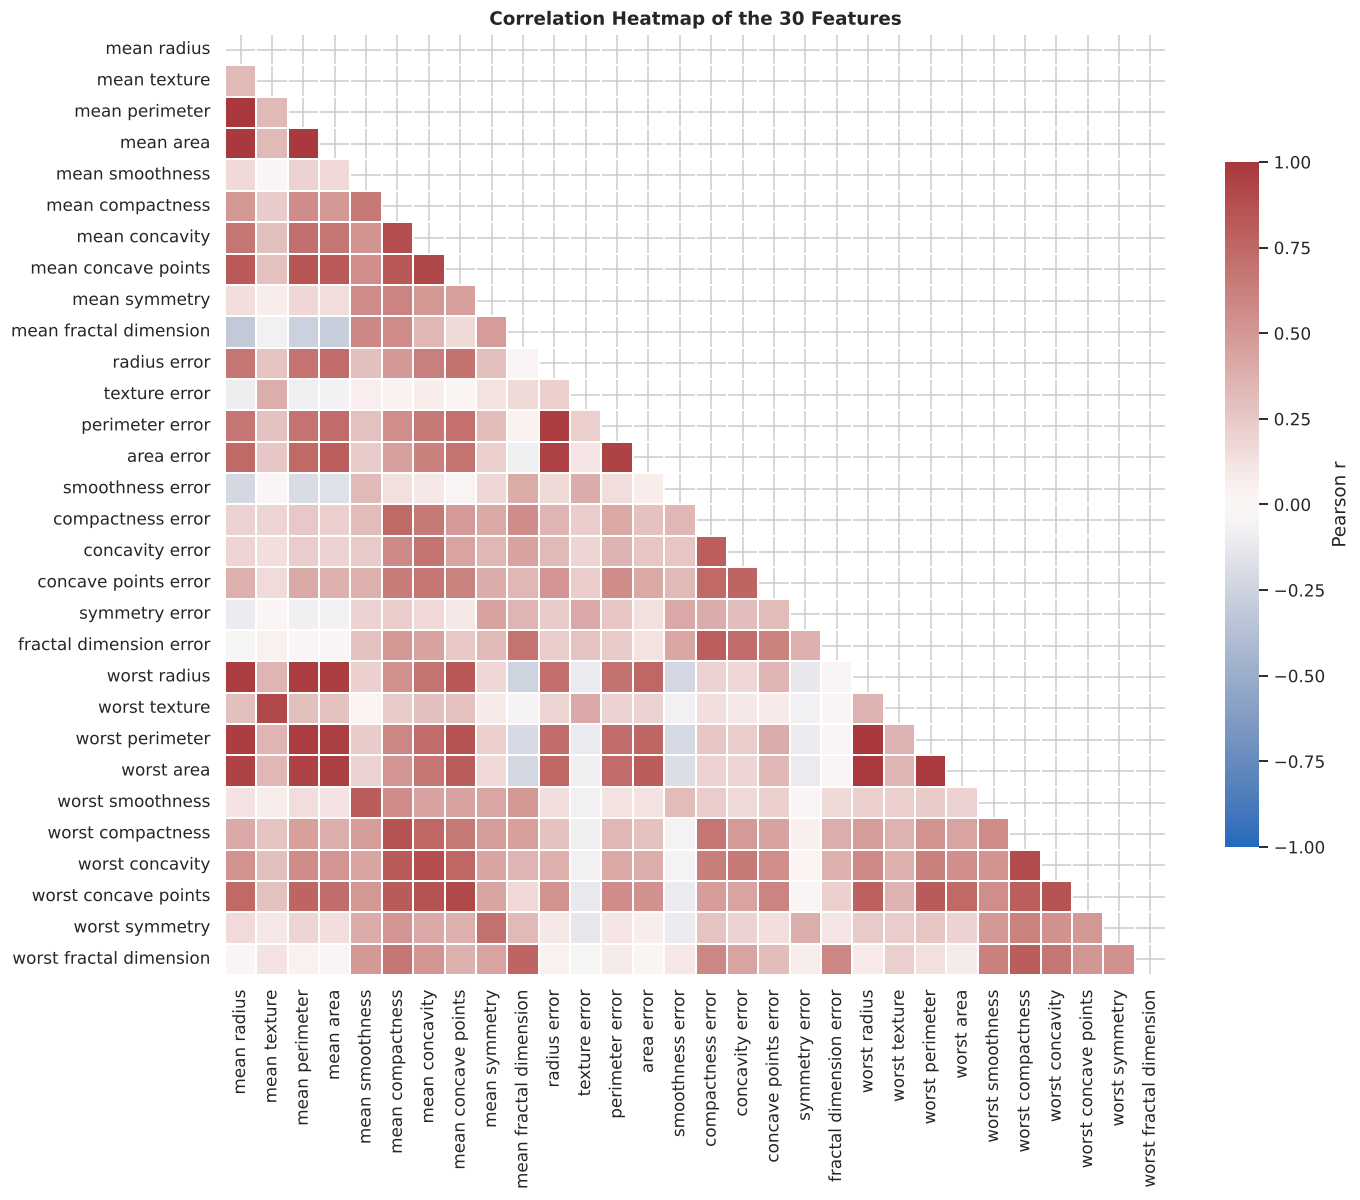

saved 04_correlation_heatmap.png


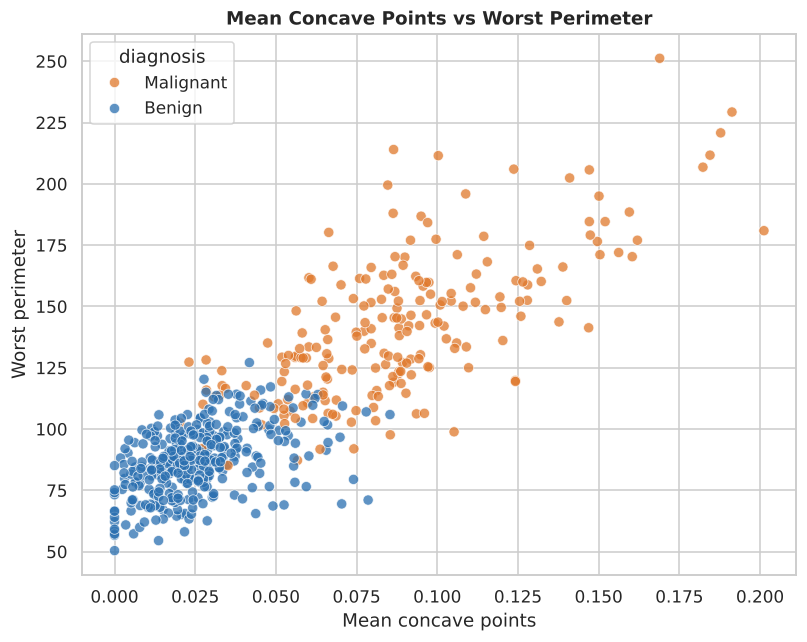

saved 05_scatter_top_features.png


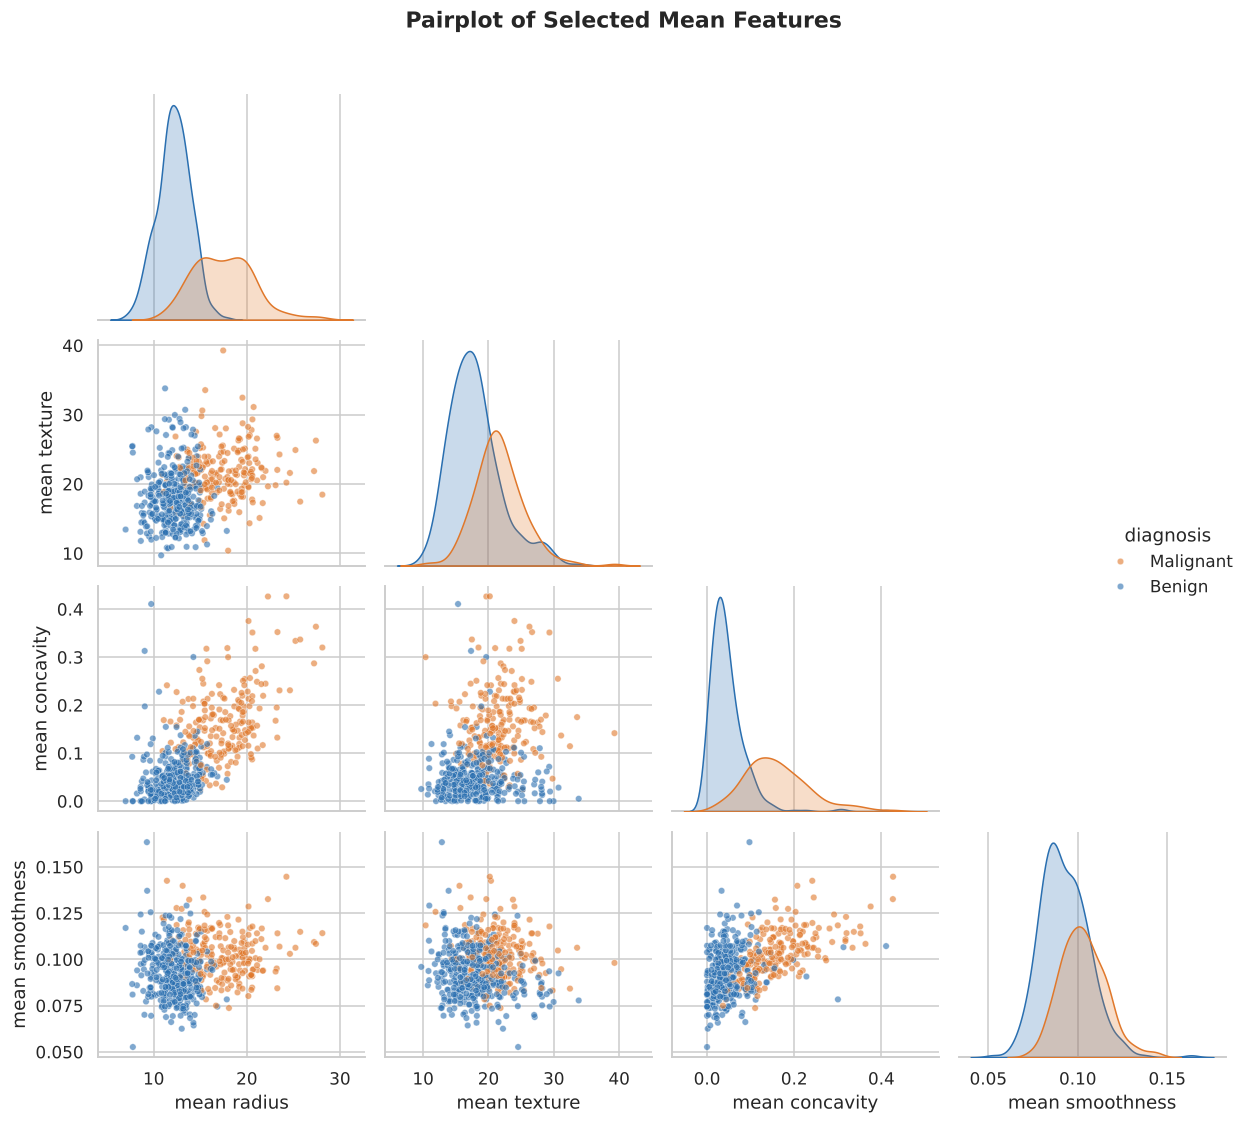

saved 06_pairplot.png


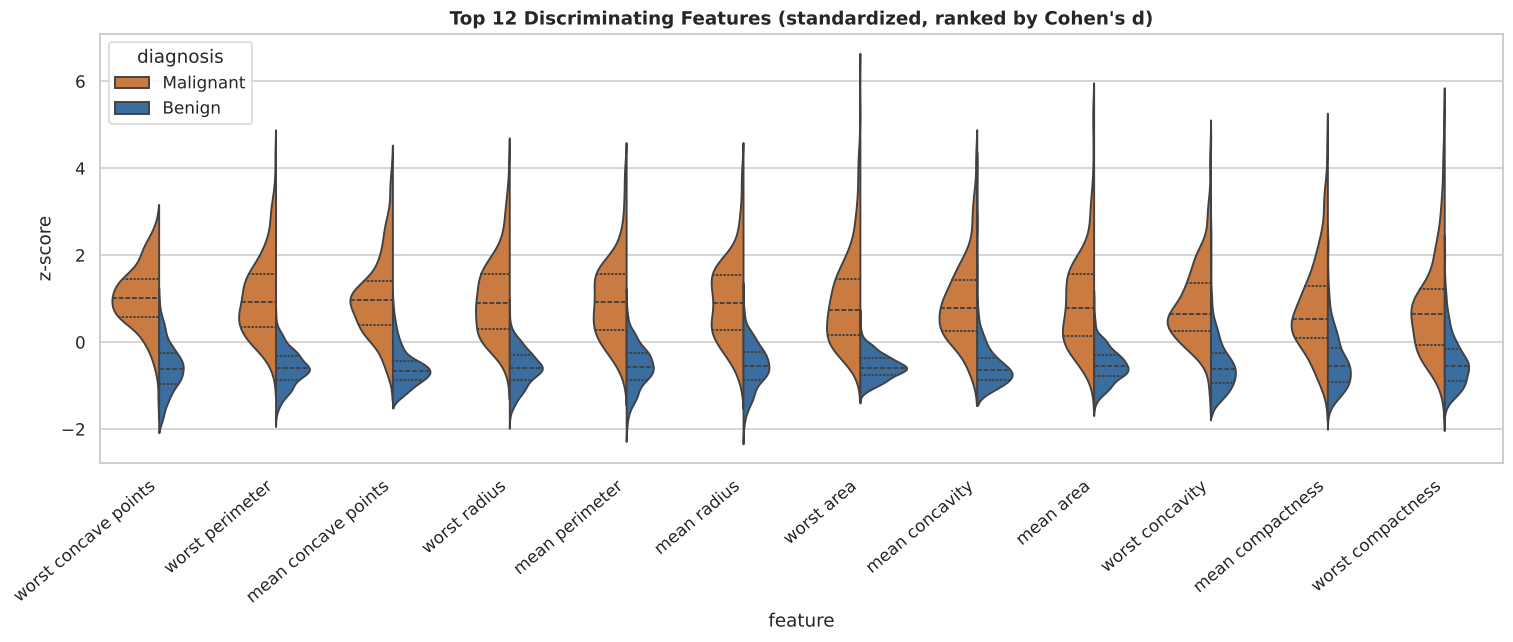

saved 07_violin_top_features.png


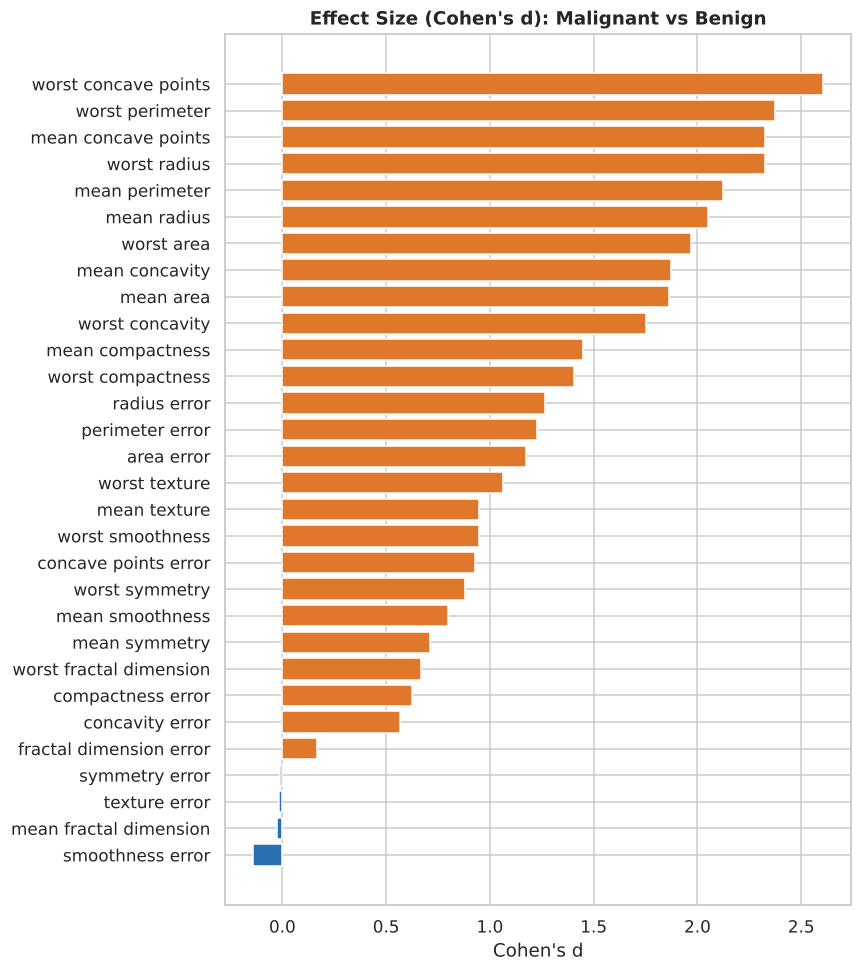

saved 08_effect_sizes.png


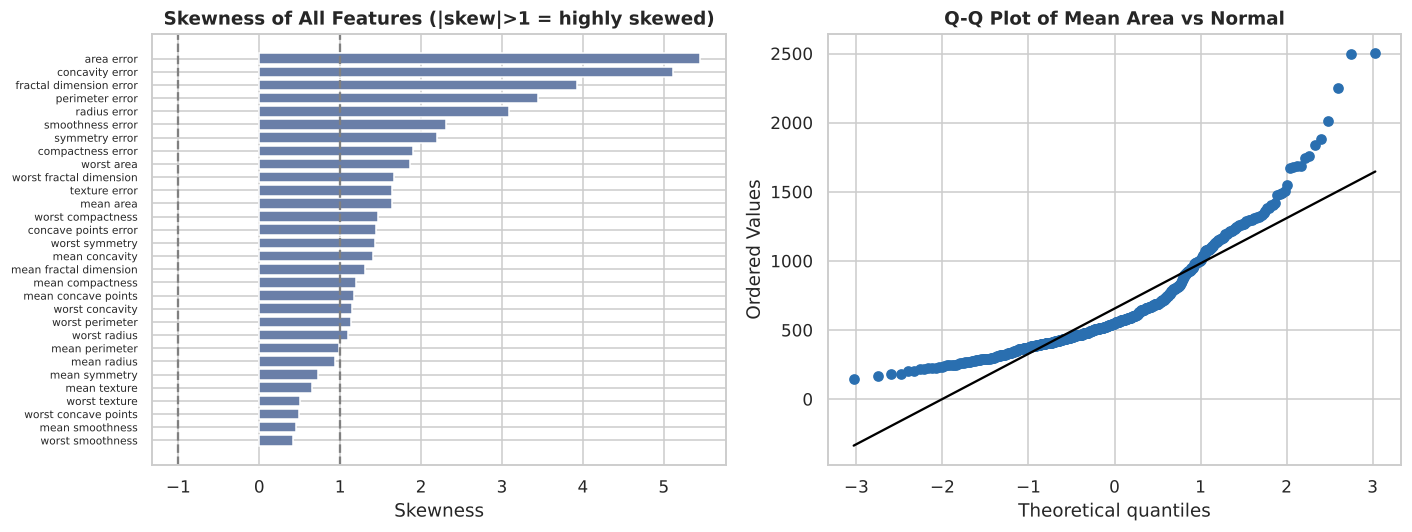

saved 09_skewness_qq.png


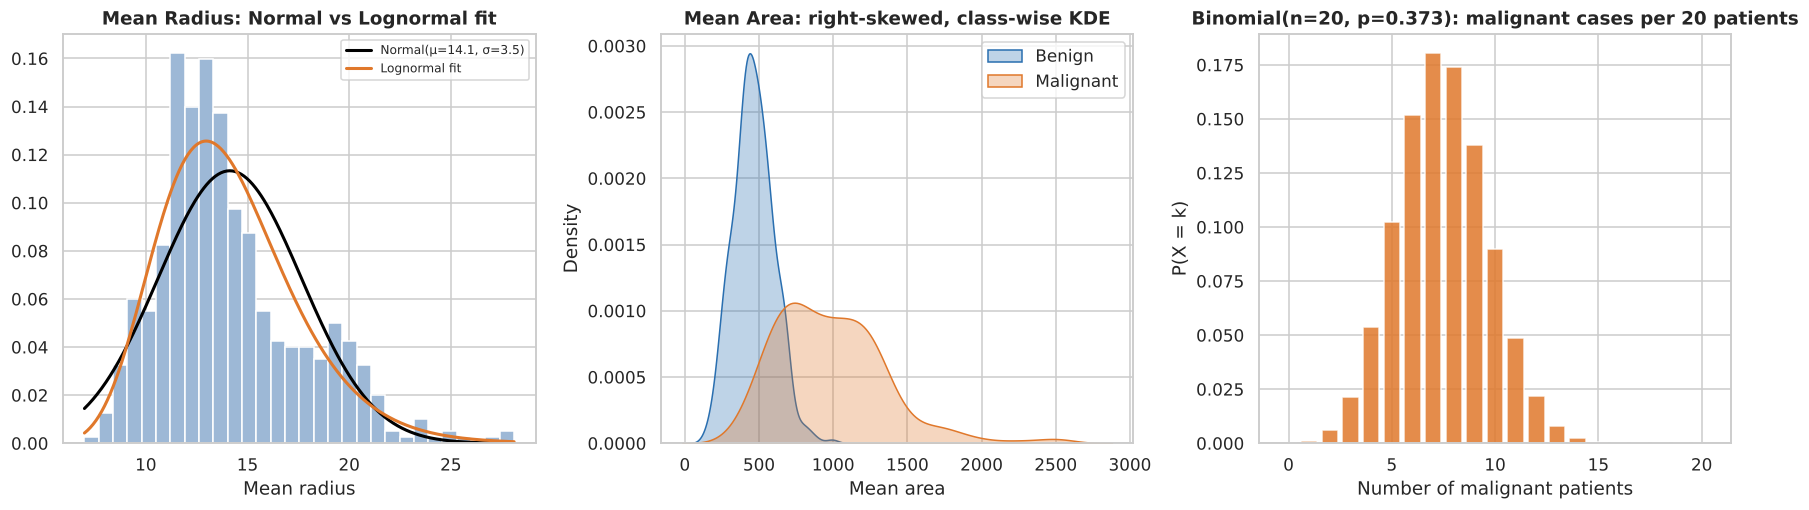

saved 10_probability_distributions.png


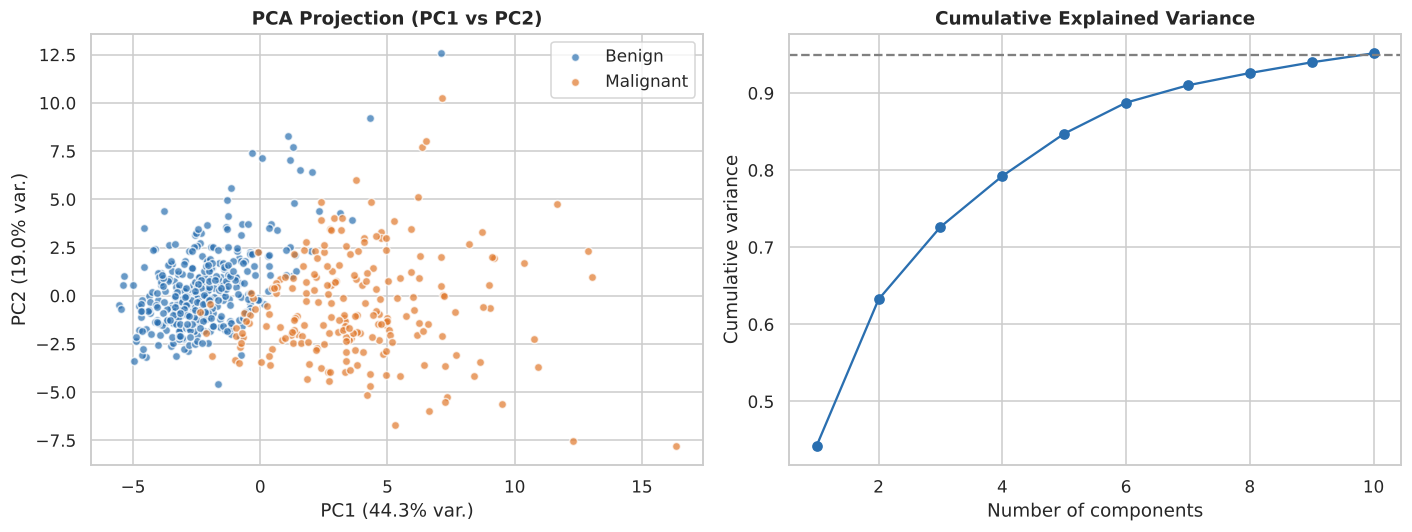

saved 11_pca.png


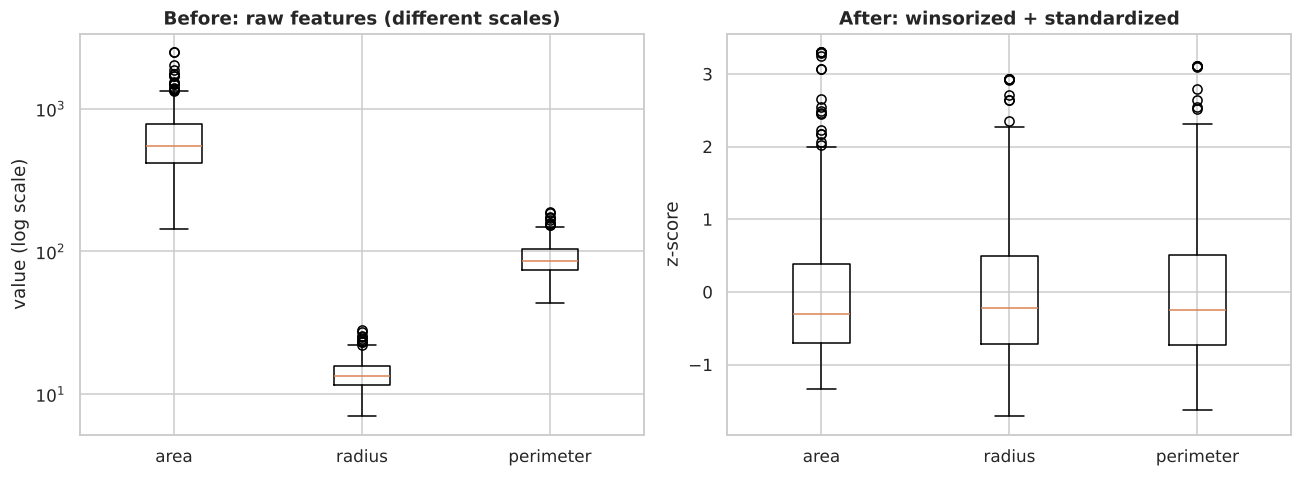

saved 12_preprocessing_before_after.png


In [7]:
# V1 – Class distribution (bar + pie) ----------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
counts = df["diagnosis"].value_counts()
sns.barplot(x=counts.index, y=counts.values, palette=PALETTE, ax=ax[0])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 5, str(v), ha="center", fontweight="bold")
ax[0].set(title="Number of Patients per Diagnosis", xlabel="Diagnosis", ylabel="Count")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
          colors=[PALETTE[k] for k in counts.index], wedgeprops={"edgecolor": "white"})
ax[1].set_title("Class Proportion")
save(fig, "01_class_distribution.png")

# V2 – Histograms + KDE by class (univariate distribution) --------------------
key_feats = ["mean radius", "mean texture", "mean area", "mean smoothness",
             "mean concavity", "mean concave points"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(axes.ravel(), key_feats):
    sns.histplot(data=df, x=c, hue="diagnosis", palette=PALETTE, kde=True,
                 stat="density", common_norm=False, alpha=0.45, ax=a)
    a.set_title(c.title())
fig.suptitle("Distribution of Key Features by Diagnosis", fontsize=14, fontweight="bold", y=1.02)
save(fig, "02_histograms_kde.png")

# V3 – Boxplots (spread & outliers) -------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(axes.ravel(), key_feats):
    sns.boxplot(data=df, x="diagnosis", y=c, palette=PALETTE, order=["Benign", "Malignant"],
                flierprops={"marker": "o", "markersize": 3}, ax=a)
    a.set_title(c.title()); a.set_xlabel("")
fig.suptitle("Boxplots of Key Features by Diagnosis (outliers shown as dots)",
             fontsize=14, fontweight="bold", y=1.02)
save(fig, "03_boxplots.png")

# V4 – Correlation heatmap (multivariate) -------------------------------------
fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, cbar_kws={"label": "Pearson r", "shrink": 0.7}, ax=ax)
ax.set_title("Correlation Heatmap of the 30 Features")
save(fig, "04_correlation_heatmap.png")

# V5 – Scatter plot of two strongest discriminators ---------------------------
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.scatterplot(data=df, x="mean concave points", y="worst perimeter", hue="diagnosis",
                palette=PALETTE, alpha=0.75, s=45, edgecolor="white", ax=ax)
ax.set(title="Mean Concave Points vs Worst Perimeter",
       xlabel="Mean concave points", ylabel="Worst perimeter")
save(fig, "05_scatter_top_features.png")

# V6 – Pairplot of 4 features --------------------------------------------------
pp_feats = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
g = sns.pairplot(df, vars=pp_feats, hue="diagnosis", palette=PALETTE, corner=True,
                 plot_kws={"alpha": 0.6, "s": 18}, diag_kind="kde")
g.figure.suptitle("Pairplot of Selected Mean Features", y=1.02, fontweight="bold")
save(g.figure, "06_pairplot.png")

# V7 – Violin plots of standardized features (ranked by effect size) ---------
top12 = tests.head(12)["feature"].tolist()
zdf = df[feature_cols].copy()
zdf = (zdf - zdf.mean()) / zdf.std()
zdf["diagnosis"] = df["diagnosis"]
long = zdf.melt(id_vars="diagnosis", value_vars=top12, var_name="feature", value_name="z-score")
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(data=long, x="feature", y="z-score", hue="diagnosis", palette=PALETTE,
               split=True, inner="quart", ax=ax)
ax.set_title("Top 12 Discriminating Features (standardized, ranked by Cohen's d)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save(fig, "07_violin_top_features.png")

# V8 – Cohen's d effect-size bar chart ----------------------------------------
fig, ax = plt.subplots(figsize=(8, 9))
t_sorted = tests.sort_values("cohens_d")
ax.barh(t_sorted["feature"], t_sorted["cohens_d"],
        color=[PALETTE["Malignant"] if v > 0 else PALETTE["Benign"] for v in t_sorted["cohens_d"]])
ax.set(title="Effect Size (Cohen's d): Malignant vs Benign", xlabel="Cohen's d")
save(fig, "08_effect_sizes.png")

# V9 – Distribution analysis: skewness + Q-Q plots ----------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sk = desc["skew"].sort_values()
ax[0].barh(sk.index, sk.values, color="#6a7fa8")
ax[0].axvline(1, ls="--", c="grey"); ax[0].axvline(-1, ls="--", c="grey")
ax[0].set(title="Skewness of All Features (|skew|>1 = highly skewed)", xlabel="Skewness")
ax[0].tick_params(axis="y", labelsize=7)
stats.probplot(df["mean area"], dist="norm", plot=ax[1])
ax[1].set_title("Q-Q Plot of Mean Area vs Normal")
ax[1].get_lines()[0].set_color(PALETTE["Benign"]); ax[1].get_lines()[1].set_color("black")
save(fig, "09_skewness_qq.png")

# V10 – Probability distributions: continuous fits + discrete binomial --------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
# (a) mean radius with fitted Normal
r = df["mean radius"]
mu, sd = stats.norm.fit(r)
xs = np.linspace(r.min(), r.max(), 300)
ax[0].hist(r, bins=30, density=True, color="#9db8d6", edgecolor="white")
ax[0].plot(xs, stats.norm.pdf(xs, mu, sd), c="black", lw=2, label=f"Normal(μ={mu:.1f}, σ={sd:.1f})")
sh, loc, sc = stats.lognorm.fit(r, floc=0)
ax[0].plot(xs, stats.lognorm.pdf(xs, sh, loc, sc), c=PALETTE["Malignant"], lw=2, label="Lognormal fit")
ax[0].set(title="Mean Radius: Normal vs Lognormal fit", xlabel="Mean radius"); ax[0].legend(fontsize=8)
ks_norm = stats.kstest(r, stats.norm(mu, sd).cdf).statistic
ks_logn = stats.kstest(r, stats.lognorm(sh, loc, sc).cdf).statistic
results["ks_mean_radius"] = {"normal": round(ks_norm, 4), "lognormal": round(ks_logn, 4)}
# (b) mean area per class – right-skewed (shows non-normality)
for cls, g_ in df.groupby("diagnosis"):
    sns.kdeplot(g_["mean area"], color=PALETTE[cls], fill=True, alpha=0.3, label=cls, ax=ax[1])
ax[1].set(title="Mean Area: right-skewed, class-wise KDE", xlabel="Mean area"); ax[1].legend()
# (c) discrete: Binomial model for number of malignant in a sample of n=20 patients
p_mal = y.mean(); n_b = 20
k = np.arange(0, n_b + 1)
ax[2].bar(k, stats.binom.pmf(k, n_b, p_mal), color=PALETTE["Malignant"], alpha=0.85)
ax[2].set(title=f"Binomial(n={n_b}, p={p_mal:.3f}): malignant cases per 20 patients",
          xlabel="Number of malignant patients", ylabel="P(X = k)")
results["binomial"] = {"p_malignant": round(p_mal, 4), "n": n_b,
                       "expected": round(n_b * p_mal, 2),
                       "P(X>=10)": round(1 - stats.binom.cdf(9, n_b, p_mal), 4)}
save(fig, "10_probability_distributions.png")

# V11 – PCA projection ---------------------------------------------------------
pca = PCA(n_components=10).fit(StandardScaler().fit_transform(X))
Z = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for cls in ["Benign", "Malignant"]:
    m = (df["diagnosis"] == cls).values
    ax[0].scatter(Z[m, 0], Z[m, 1], c=PALETTE[cls], label=cls, alpha=0.7, s=28, edgecolor="white")
ax[0].set(title="PCA Projection (PC1 vs PC2)",
          xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var.)",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var.)"); ax[0].legend()
cum = np.cumsum(pca.explained_variance_ratio_)
ax[1].plot(range(1, 11), cum, "o-", c=PALETTE["Benign"])
ax[1].axhline(0.95, ls="--", c="grey"); ax[1].set(title="Cumulative Explained Variance",
          xlabel="Number of components", ylabel="Cumulative variance")
results["pca"] = {"pc1": round(pca.explained_variance_ratio_[0], 4),
                  "pc2": round(pca.explained_variance_ratio_[1], 4),
                  "cum_pc1_2": round(cum[1], 4),
                  "components_for_95pct": int(np.argmax(cum >= 0.95) + 1)}
save(fig, "11_pca.png")

# V12 – Before vs after preprocessing ----------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].boxplot([X_train["mean area"], X_train["mean radius"], X_train["mean perimeter"]],
              tick_labels=["area", "radius", "perimeter"])
ax[0].set(title="Before: raw features (different scales)", yscale="log", ylabel="value (log scale)")
ax[1].boxplot([Xtr[:, feature_cols.index(c)] for c in ["mean area", "mean radius", "mean perimeter"]],
              tick_labels=["area", "radius", "perimeter"])
ax[1].set(title="After: winsorized + standardized", ylabel="z-score")
save(fig, "12_preprocessing_before_after.png")

## 5. Deep learning model – PyTorch MLP

Best config: {'hidden': '(64, 32)', 'lr': 0.01, 'dropout': 0.3}


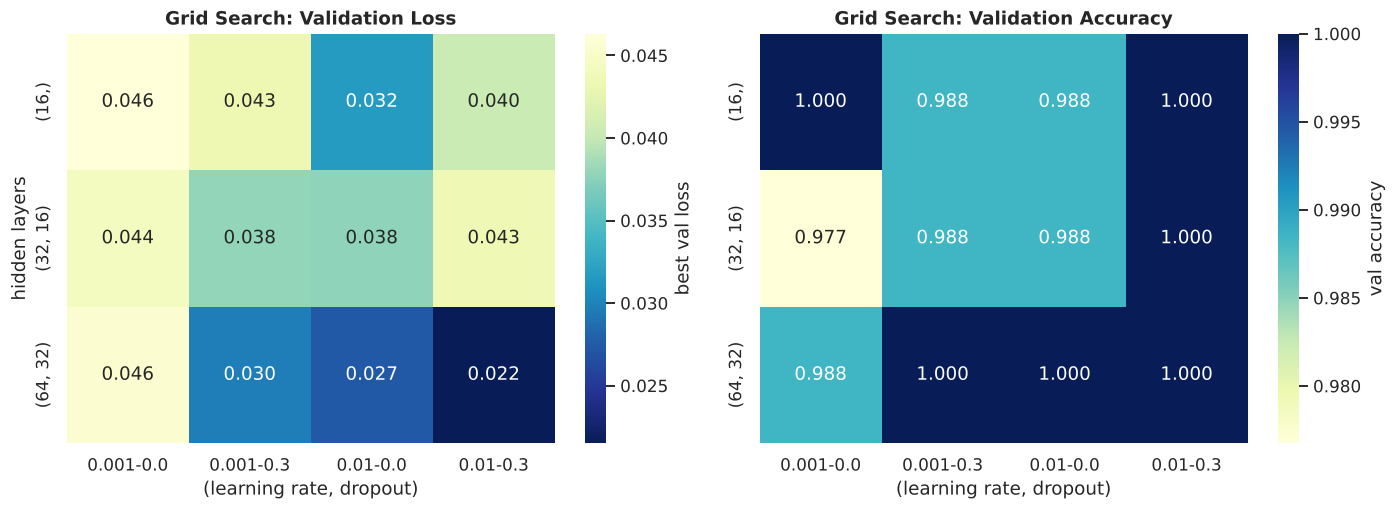

saved 13_hyperparameter_tuning.png


In [8]:
class MLP(nn.Module):
    """Fully-connected network: [Linear -> BatchNorm -> ReLU -> Dropout] x N -> Linear(1)."""
    def __init__(self, in_dim, hidden, dropout):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))          # logit output (sigmoid inside the loss)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


def to_t(a, dtype=torch.float32):
    return torch.tensor(np.asarray(a), dtype=dtype)


Ttr, Tva, Tte = to_t(Xtr), to_t(Xva), to_t(Xte)
ytr_t, yva_t, yte_t = to_t(y_train), to_t(y_val), to_t(y_test)


def train_model(hidden, lr, dropout, weight_decay=1e-4, max_epochs=200, patience=20,
                batch=32, seed=SEED, verbose=False):
    """Train with Adam + BCE-with-logits and early stopping on validation loss."""
    torch.manual_seed(seed)
    model = MLP(Xtr.shape[1], hidden, dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    lossf = nn.BCEWithLogitsLoss()
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, best_state, wait = np.inf, None, 0
    n = len(Ttr)
    for ep in range(max_epochs):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            if len(idx) < 2:                       # BatchNorm needs >1 sample
                continue
            opt.zero_grad()
            loss = lossf(model(Ttr[idx]), ytr_t[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            ltr, lva = model(Ttr), model(Tva)
            hist["train_loss"].append(lossf(ltr, ytr_t).item())
            hist["val_loss"].append(lossf(lva, yva_t).item())
            hist["train_acc"].append(((ltr > 0).float() == ytr_t).float().mean().item())
            hist["val_acc"].append(((lva > 0).float() == yva_t).float().mean().item())
        if hist["val_loss"][-1] < best - 1e-4:
            best, wait = hist["val_loss"][-1], 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    hist["best_epoch"] = int(np.argmin(hist["val_loss"]) + 1)
    return model, hist


# 5a. Basic hyper-parameter tuning (grid search on the VALIDATION set) --------
grid = [(h, lr, dr)
        for h in [(16,), (32, 16), (64, 32)]
        for lr in [1e-3, 1e-2]
        for dr in [0.0, 0.3]]
tune_rows = []
for hidden, lr, dr in grid:
    m, h = train_model(hidden, lr, dr)
    with torch.no_grad():
        pv = torch.sigmoid(m(Tva)).numpy()
    tune_rows.append({"hidden": str(hidden), "lr": lr, "dropout": dr,
                      "val_auc": roc_auc_score(y_val, pv),
                      "val_acc": accuracy_score(y_val, pv > 0.5),
                      "val_loss": min(h["val_loss"]), "best_epoch": h["best_epoch"]})
tune = pd.DataFrame(tune_rows).sort_values(["val_loss"]).reset_index(drop=True)
tune.round(4).to_csv(os.path.join(RES_DIR, "hyperparameter_tuning.csv"), index=False)
best_cfg = tune.iloc[0]
best_hidden = eval(best_cfg["hidden"])
results["best_hyperparameters"] = {"hidden": best_cfg["hidden"], "lr": float(best_cfg["lr"]),
                                   "dropout": float(best_cfg["dropout"])}
print("Best config:", results["best_hyperparameters"])

# tuning visual
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
piv = tune.pivot_table(index="hidden", columns=["lr", "dropout"], values="val_loss")
sns.heatmap(piv, annot=True, fmt=".3f", cmap="YlGnBu_r", ax=ax[0], cbar_kws={"label": "best val loss"})
ax[0].set(title="Grid Search: Validation Loss", xlabel="(learning rate, dropout)", ylabel="hidden layers")
piv2 = tune.pivot_table(index="hidden", columns=["lr", "dropout"], values="val_acc")
sns.heatmap(piv2, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax[1], cbar_kws={"label": "val accuracy"})
ax[1].set(title="Grid Search: Validation Accuracy", xlabel="(learning rate, dropout)", ylabel="")
save(fig, "13_hyperparameter_tuning.png")

# 5b. Final model --------------------------------------------------------------
model, hist = train_model(best_hidden, float(best_cfg["lr"]), float(best_cfg["dropout"]))
n_params = sum(p.numel() for p in model.parameters())
results["model"] = {"architecture": f"30 -> {' -> '.join(map(str, best_hidden))} -> 1",
                    "parameters": n_params, "epochs_run": len(hist["train_loss"]),
                    "best_epoch": hist["best_epoch"], "optimizer": "Adam", "loss": "BCEWithLogits",
                    "weight_decay": 1e-4, "batch_size": 32, "early_stopping_patience": 20}

## 6. Evaluation (held-out test set) + baseline models

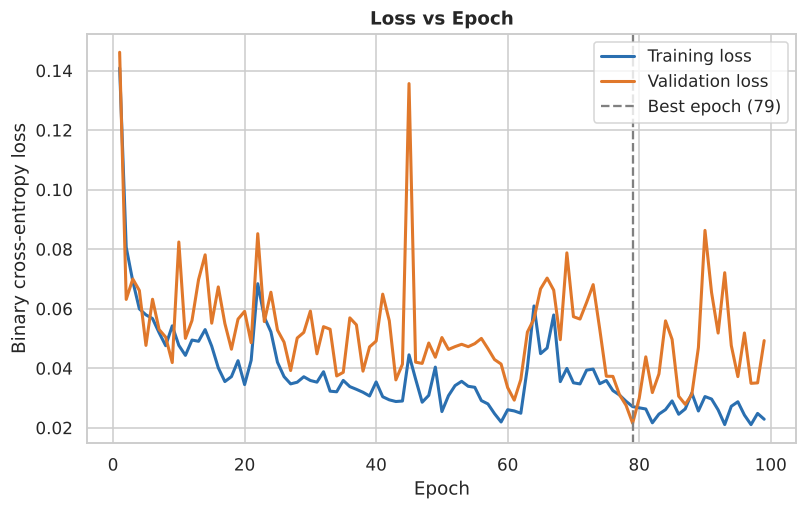

saved 14_loss_vs_epoch.png


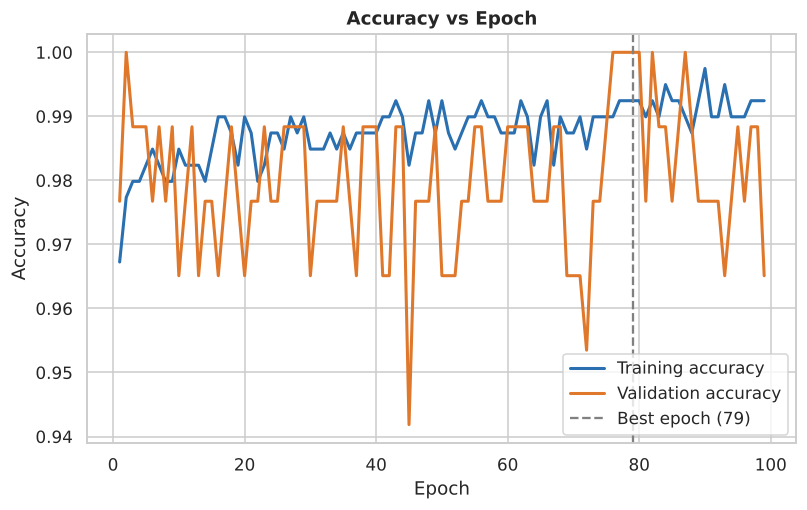

saved 15_accuracy_vs_epoch.png


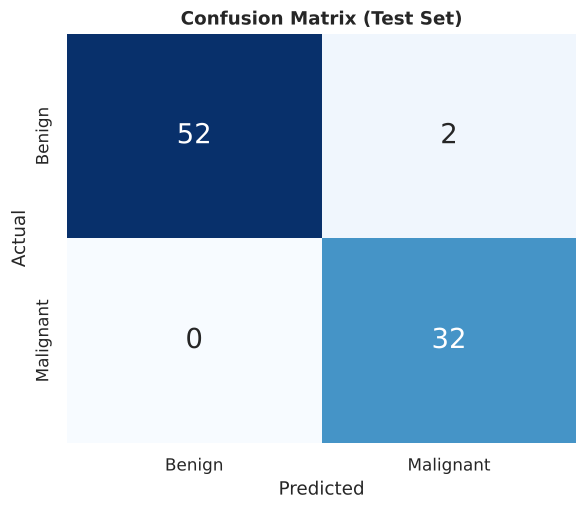

saved 16_confusion_matrix.png


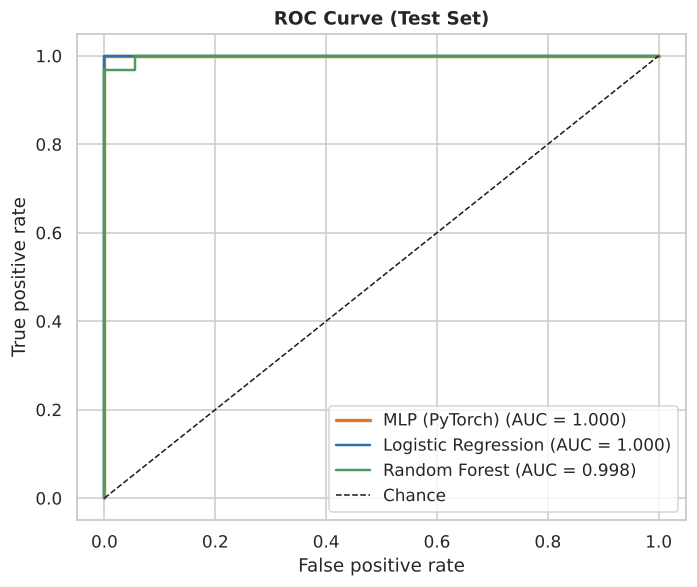

saved 17_roc_curve.png


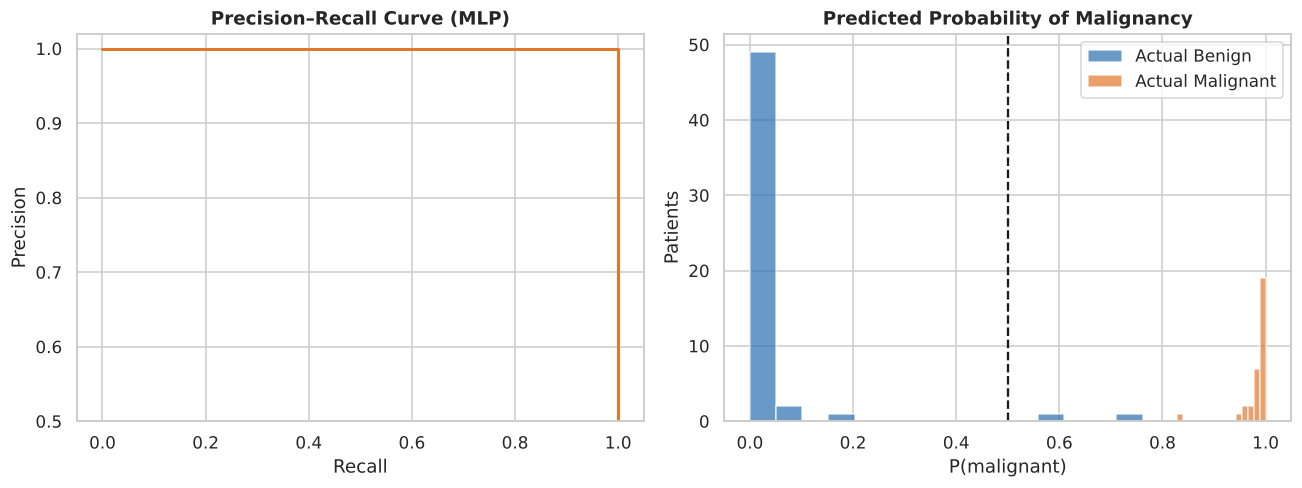

saved 18_pr_curve_probabilities.png


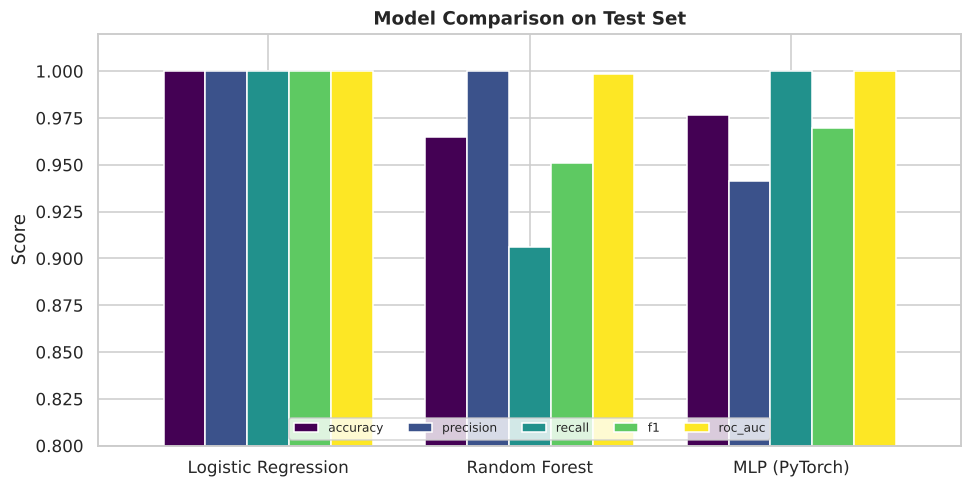

saved 19_model_comparison.png


In [9]:
with torch.no_grad():
    p_test = torch.sigmoid(model(Tte)).numpy()
pred = (p_test > 0.5).astype(int)
metrics = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
           "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
           "roc_auc": roc_auc_score(y_test, p_test)}
results["mlp_test_metrics"] = {k: round(float(v), 4) for k, v in metrics.items()}
cm = confusion_matrix(y_test, pred)
results["confusion_matrix"] = cm.tolist()

# Baselines for context
base = {}
lr_m = LogisticRegression(max_iter=2000).fit(Xtr, y_train)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(Xtr, y_train)
for name, mdl in [("Logistic Regression", lr_m), ("Random Forest", rf)]:
    pr = mdl.predict_proba(Xte)[:, 1]
    base[name] = {"accuracy": accuracy_score(y_test, pr > .5), "precision": precision_score(y_test, pr > .5),
                  "recall": recall_score(y_test, pr > .5), "f1": f1_score(y_test, pr > .5),
                  "roc_auc": roc_auc_score(y_test, pr)}
base["MLP (PyTorch)"] = metrics
comp = pd.DataFrame(base).T.round(4)
comp.to_csv(os.path.join(RES_DIR, "model_comparison.csv"))
results["model_comparison"] = comp.to_dict("index")

# Robustness: repeat final training with 10 different seeds
seed_metrics = []
for s in range(10):
    m_s, _ = train_model(best_hidden, float(best_cfg["lr"]), float(best_cfg["dropout"]), seed=100 + s)
    with torch.no_grad():
        ps = torch.sigmoid(m_s(Tte)).numpy()
    seed_metrics.append((accuracy_score(y_test, ps > .5), roc_auc_score(y_test, ps)))
sm = np.array(seed_metrics)
results["seed_robustness"] = {"acc_mean": round(sm[:, 0].mean(), 4), "acc_std": round(sm[:, 0].std(), 4),
                              "auc_mean": round(sm[:, 1].mean(), 4), "auc_std": round(sm[:, 1].std(), 4)}

# R1 – Loss vs epoch ----------------------------------------------------------
ep = np.arange(1, len(hist["train_loss"]) + 1)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(ep, hist["train_loss"], label="Training loss", c=PALETTE["Benign"], lw=2)
ax.plot(ep, hist["val_loss"], label="Validation loss", c=PALETTE["Malignant"], lw=2)
ax.axvline(hist["best_epoch"], ls="--", c="grey", label=f"Best epoch ({hist['best_epoch']})")
ax.set(title="Loss vs Epoch", xlabel="Epoch", ylabel="Binary cross-entropy loss"); ax.legend()
save(fig, "14_loss_vs_epoch.png")

# R2 – Accuracy vs epoch ------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(ep, hist["train_acc"], label="Training accuracy", c=PALETTE["Benign"], lw=2)
ax.plot(ep, hist["val_acc"], label="Validation accuracy", c=PALETTE["Malignant"], lw=2)
ax.axvline(hist["best_epoch"], ls="--", c="grey", label=f"Best epoch ({hist['best_epoch']})")
ax.set(title="Accuracy vs Epoch", xlabel="Epoch", ylabel="Accuracy"); ax.legend(loc="lower right")
save(fig, "15_accuracy_vs_epoch.png")

# R3 – Confusion matrix -------------------------------------------------------
fig, ax = plt.subplots(figsize=(5.5, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 18},
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"], ax=ax)
ax.set(title="Confusion Matrix (Test Set)", xlabel="Predicted", ylabel="Actual")
save(fig, "16_confusion_matrix.png")

# R4 – ROC curves (MLP + baselines) ------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, probs, col in [("MLP (PyTorch)", p_test, PALETTE["Malignant"]),
                         ("Logistic Regression", lr_m.predict_proba(Xte)[:, 1], PALETTE["Benign"]),
                         ("Random Forest", rf.predict_proba(Xte)[:, 1], "#4c9a5c")]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, lw=2.2 if "MLP" in name else 1.6, c=col, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set(title="ROC Curve (Test Set)", xlabel="False positive rate", ylabel="True positive rate"); ax.legend(loc="lower right")
save(fig, "17_roc_curve.png")

# R5 – Precision–recall & predicted probability distribution -----------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
prec, rec, _ = precision_recall_curve(y_test, p_test)
ax[0].plot(rec, prec, c=PALETTE["Malignant"], lw=2)
ax[0].set(title="Precision–Recall Curve (MLP)", xlabel="Recall", ylabel="Precision", ylim=(0.5, 1.02))
for lab, name in [(0, "Benign"), (1, "Malignant")]:
    ax[1].hist(p_test[y_test == lab], bins=15, alpha=0.7, color=PALETTE[name], label=f"Actual {name}")
ax[1].axvline(0.5, ls="--", c="k"); ax[1].set(title="Predicted Probability of Malignancy",
          xlabel="P(malignant)", ylabel="Patients"); ax[1].legend()
save(fig, "18_pr_curve_probabilities.png")

# R6 – Model comparison -------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.6))
comp[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot.bar(ax=ax, width=0.8, colormap="viridis")
ax.set(title="Model Comparison on Test Set", ylim=(0.8, 1.02), ylabel="Score"); ax.legend(ncol=5, fontsize=8, loc="lower center")
plt.setp(ax.get_xticklabels(), rotation=0)
save(fig, "19_model_comparison.png")

## 7. Feature analysis / importance

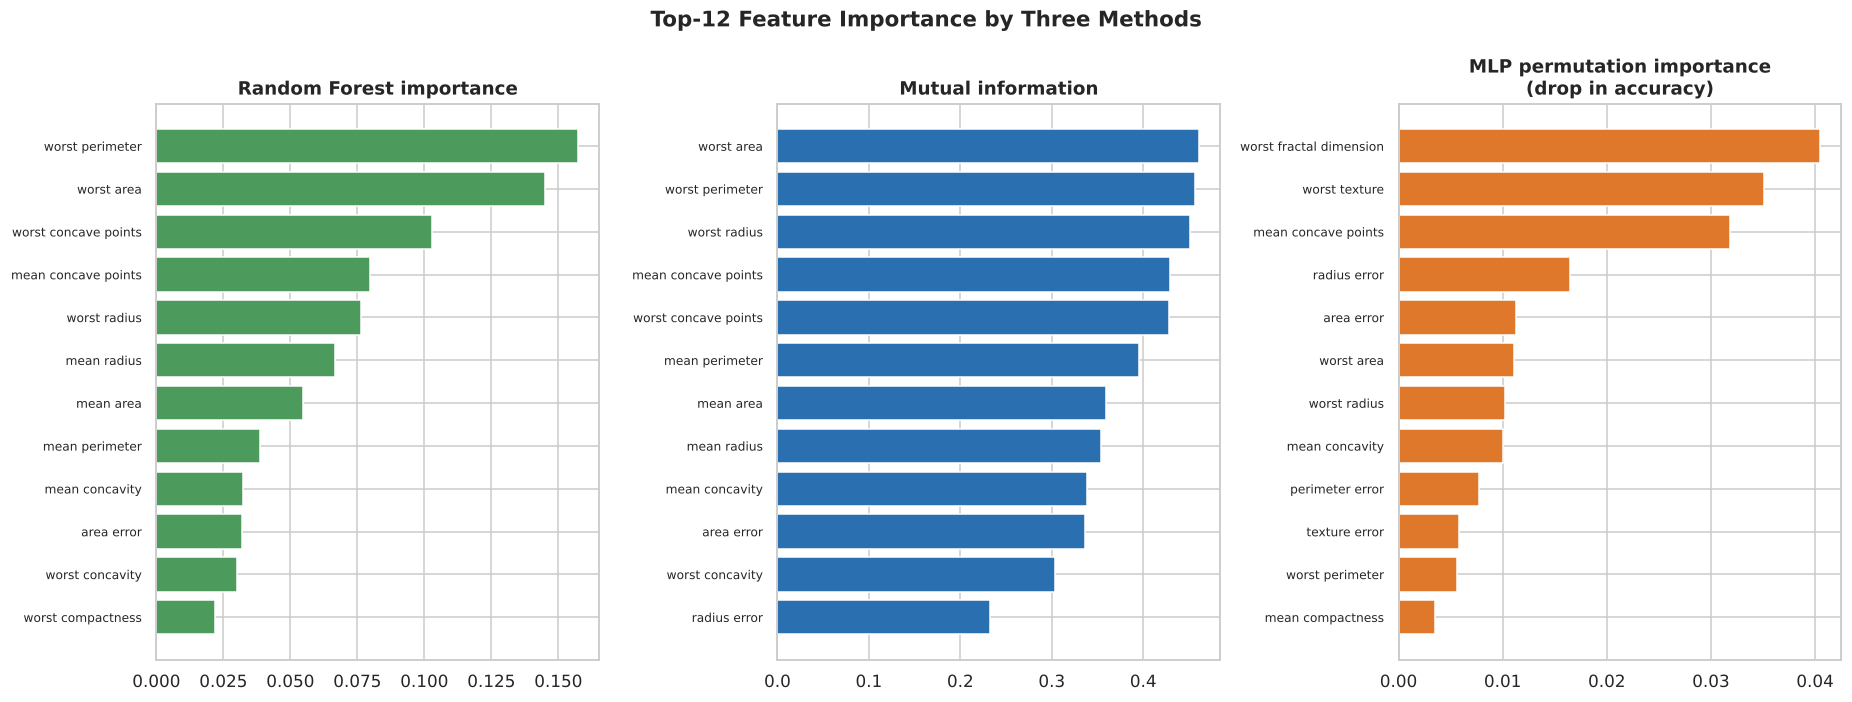

saved 20_feature_importance.png


In [10]:
def permutation_importance_torch(mdl, X_t, y_np, n_repeats=30, seed=SEED):
    """Drop in ROC-AUC (or accuracy) when a single feature is shuffled."""
    rng = np.random.default_rng(seed)
    with torch.no_grad():
        base_acc = accuracy_score(y_np, torch.sigmoid(mdl(X_t)).numpy() > .5)
    imp = np.zeros(X_t.shape[1])
    for j in range(X_t.shape[1]):
        drops = []
        for _ in range(n_repeats):
            Xp = X_t.clone()
            Xp[:, j] = Xp[torch.tensor(rng.permutation(len(Xp))), j]
            with torch.no_grad():
                a = accuracy_score(y_np, torch.sigmoid(mdl(Xp)).numpy() > .5)
            drops.append(base_acc - a)
        imp[j] = np.mean(drops)
    return imp


# use validation + test together for a less noisy estimate
Tvt = torch.cat([Tva, Tte]); yvt = np.concatenate([y_val, y_test])
perm_imp = permutation_importance_torch(model, Tvt, yvt)
rf_imp = rf.feature_importances_
mi = mutual_info_classif(Xtr, y_train, random_state=SEED)
fi = pd.DataFrame({"feature": feature_cols, "mlp_permutation": perm_imp,
                   "random_forest": rf_imp, "mutual_info": mi}).set_index("feature")
fi.round(4).sort_values("random_forest", ascending=False).to_csv(os.path.join(RES_DIR, "feature_importance.csv"))
results["top5_rf_importance"] = fi["random_forest"].sort_values(ascending=False).head(5).round(4).to_dict()
results["top5_mlp_permutation"] = fi["mlp_permutation"].sort_values(ascending=False).head(5).round(4).to_dict()
results["top5_mutual_info"] = fi["mutual_info"].sort_values(ascending=False).head(5).round(4).to_dict()
rho = stats.spearmanr(fi["random_forest"], fi["mutual_info"])[0]
results["spearman_rf_vs_mi"] = round(float(rho), 3)

fig, ax = plt.subplots(1, 3, figsize=(17, 6.5), sharey=False)
for a, col, title, color in zip(ax, ["random_forest", "mutual_info", "mlp_permutation"],
                               ["Random Forest importance", "Mutual information",
                                "MLP permutation importance\n(drop in accuracy)"],
                               ["#4c9a5c", PALETTE["Benign"], PALETTE["Malignant"]]):
    s = fi[col].sort_values().tail(12)
    a.barh(s.index, s.values, color=color); a.set_title(title); a.tick_params(axis="y", labelsize=8)
fig.suptitle("Top-12 Feature Importance by Three Methods", fontsize=14, fontweight="bold")
save(fig, "20_feature_importance.png")

## Save all numbers

In [11]:
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

with open(os.path.join(RES_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2, default=jsonable)
print(json.dumps(results, indent=2, default=jsonable))
print("DONE")

{
  "shape": [
    569,
    31
  ],
  "n_features": 30,
  "class_counts": {
    "Benign": 357,
    "Malignant": 212
  },
  "missing_values": 0,
  "duplicate_rows": 0,
  "outliers_total_flags": 608,
  "outliers_top5": {
    "area error": 65,
    "radius error": 38,
    "perimeter error": 38,
    "worst area": 35,
    "smoothness error": 30
  },
  "rows_with_any_outlier": 171,
  "n_skewed_gt1": 22,
  "top_effect_sizes": [
    {
      "feature": "worst concave points",
      "cohens_d": 2.6
    },
    {
      "feature": "worst perimeter",
      "cohens_d": 2.37
    },
    {
      "feature": "mean concave points",
      "cohens_d": 2.33
    },
    {
      "feature": "worst radius",
      "cohens_d": 2.32
    },
    {
      "feature": "mean perimeter",
      "cohens_d": 2.12
    }
  ],
  "n_significant_features_p<0.05": 27,
  "n_pairs_corr_gt_0.9": 21,
  "top_corr_pairs": [
    [
      "mean radius",
      "mean perimeter",
      0.998
    ],
    [
      "worst radius",
      "worst perimet